<a href="https://colab.research.google.com/github/yibesh/DeepLearning/blob/main/CNN_detail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Convolutional Neural Networks (CNNs): A Step-by-Step Teaching Notebook


**Goal:** See how images become numbers, how convolution filters detect patterns, and how a small CNN learns to classify handwritten digits.



## 1. Import libraries

We use NumPy for array operations, Matplotlib for pictures, and TensorFlow/Keras for the CNN.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. An image is a grid of pixel values

A grayscale image has one value per pixel. Here, a bright square is placed on a dark background. Real images are much larger, but the principle is the same.

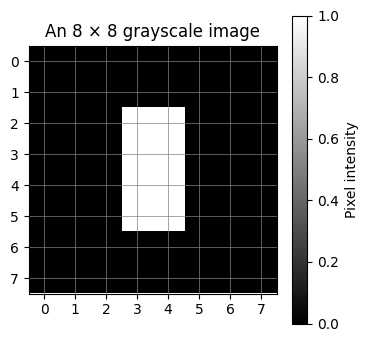

Image shape: (8, 8)
[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]]


In [ ]:
# Create a small synthetic grayscale image (0 = black, 1 = white)
image = np.zeros((8, 8), dtype=np.float32)
image[2:6, 3:5] = 1.0  # a simple vertical bright bar

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("An 8 × 8 grayscale image")
plt.xticks(range(8))
plt.yticks(range(8))
plt.grid(color="gray", linewidth=0.5)
plt.colorbar(label="Pixel intensity")
plt.show()

print("Image shape:", image.shape)
print(image)

## 3. Convolution intuition: slide a filter over the image

A filter (kernel) is a small grid of weights. At each position, multiply the overlapping image values by the filter weights and add the results. The output grid is called a **feature map**.

The next example uses a simple vertical-edge filter. This is a hand-crafted teaching example; real CNN filters are usually learned from data.

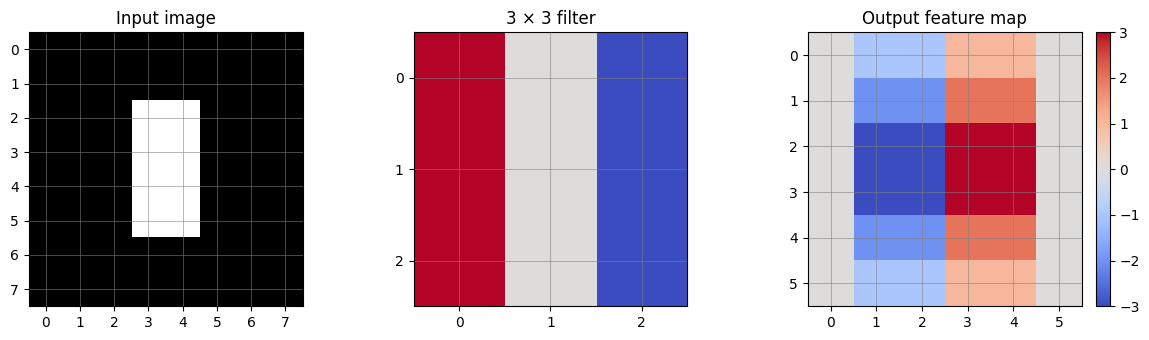

Input shape: (8, 8)
Kernel shape: (3, 3)
Feature-map shape: (6, 6)


In [ ]:
# A simple vertical-edge filter (kernel)
kernel = np.array([
    [ 1, 0, -1],
    [ 1, 0, -1],
    [ 1, 0, -1]
], dtype=np.float32)

def simple_convolution2d(image, kernel):
    # Educational implementation of valid 2-D cross-correlation.
    # Deep-learning libraries commonly call this operation convolution,
    # although the kernel is not flipped as in strict mathematical convolution.
    h, w = image.shape
    kh, kw = kernel.shape
    output = np.zeros((h - kh + 1, w - kw + 1), dtype=np.float32)
    for row in range(output.shape[0]):
        for col in range(output.shape[1]):
            patch = image[row:row+kh, col:col+kw]
            output[row, col] = np.sum(patch * kernel)
    return output

feature_map = simple_convolution2d(image, kernel)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Input image")
axes[1].imshow(kernel, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("3 × 3 filter")
im = axes[2].imshow(feature_map, cmap="coolwarm")
axes[2].set_title("Output feature map")
for ax in axes:
    ax.set_xticks(range(ax.images[0].get_array().shape[1]))
    ax.set_yticks(range(ax.images[0].get_array().shape[0]))
    ax.grid(color="gray", linewidth=0.4)
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("Input shape:", image.shape)
print("Kernel shape:", kernel.shape)
print("Feature-map shape:", feature_map.shape)

### 3A. Calculate one output value by hand

Choose the top-left 3 × 3 image patch. The operation is:

\[
(\text{patch} \odot \text{kernel})\text{ summed over all entries}
\]

Here `⊙` means element-by-element multiplication. Run the cell to see each product and the sum.

In [ ]:
patch = image[0:3, 0:3]
products = patch * kernel

print("Image patch:\n", patch)
print("\nKernel:\n", kernel)
print("\nElement-wise products:\n", products)
print("\nOutput value =", products.sum())
print("This value becomes the top-left cell of the feature map.")

Image patch:
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

Kernel:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

Element-wise products:
 [[ 0.  0. -0.]
 [ 0.  0. -0.]
 [ 0.  0. -0.]]

Output value = 0.0
This value becomes the top-left cell of the feature map.


## 4. Stride and padding affect output size

For a square input, the output width/height for a valid convolution is:

\[
\text{output size} = \left\lfloor\frac{N-F+2P}{S}\right\rfloor+1
\]

- `N`: input width/height
- `F`: filter width/height
- `P`: padding on each side
- `S`: stride, or how many pixels the filter moves at each step

Try changing the values below.

In [ ]:
def output_size(N, F, P=0, S=1):
    return (N - F + 2 * P) // S + 1

examples = [
    {"N": 7, "F": 3, "P": 0, "S": 1},
    {"N": 7, "F": 3, "P": 1, "S": 1},
    {"N": 7, "F": 3, "P": 0, "S": 2},
]

for ex in examples:
    out_size = output_size(**ex)
    print(f"N={ex['N']}, F={ex['F']}, P={ex['P']}, S={ex['S']} -> output {out_size} × {out_size}")

N=7, F=3, P=0, S=1 -> output 5 × 5
N=7, F=3, P=1, S=1 -> output 7 × 7
N=7, F=3, P=0, S=2 -> output 3 × 3


## 5. ReLU: keep positive activations

ReLU is defined as `ReLU(x) = max(0, x)`. It replaces negative values with zero and leaves positive values unchanged.

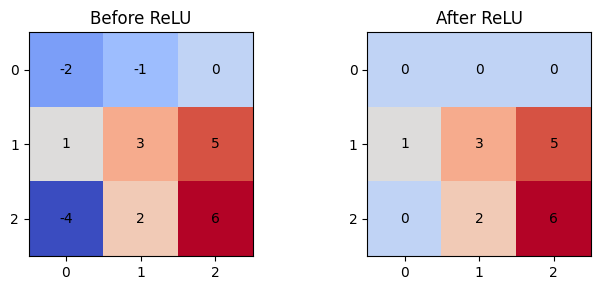

In [ ]:
example_activations = np.array([
    [-2, -1, 0],
    [ 1,  3, 5],
    [-4,  2, 6]
], dtype=np.float32)

relu_output = np.maximum(0, example_activations)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, data, title in zip(
    axes, [example_activations, relu_output], ["Before ReLU", "After ReLU"]
):
    im = ax.imshow(data, cmap="coolwarm", vmin=-4, vmax=6)
    ax.set_title(title)
    for (r, c), value in np.ndenumerate(data):
        ax.text(c, r, f"{value:g}", ha="center", va="center", color="black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
plt.tight_layout()
plt.show()

## 6. Max pooling: downsample a feature map

A 2 × 2 max-pooling operation takes the largest value from each 2 × 2 block. It reduces spatial size and can make small position changes less disruptive.

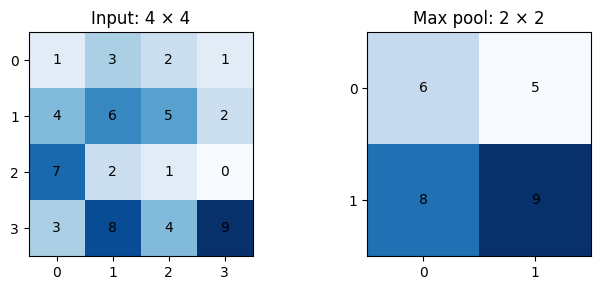

In [ ]:
pool_input = np.array([
    [1, 3, 2, 1],
    [4, 6, 5, 2],
    [7, 2, 1, 0],
    [3, 8, 4, 9]
], dtype=np.float32)

def max_pool_2x2(array):
    h, w = array.shape
    output = np.zeros((h // 2, w // 2), dtype=np.float32)
    for r in range(0, h, 2):
        for c in range(0, w, 2):
            output[r // 2, c // 2] = np.max(array[r:r+2, c:c+2])
    return output

pool_output = max_pool_2x2(pool_input)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, data, title in zip(axes, [pool_input, pool_output], ["Input: 4 × 4", "Max pool: 2 × 2"]):
    ax.imshow(data, cmap="Blues")
    ax.set_title(title)
    for (r, c), value in np.ndenumerate(data):
        ax.text(c, r, f"{value:g}", ha="center", va="center", color="black")
    ax.set_xticks(range(data.shape[1])); ax.set_yticks(range(data.shape[0]))
plt.tight_layout()
plt.show()

## 7. Load the MNIST handwritten-digit dataset

MNIST contains grayscale images of handwritten digits from 0 to 9. We normalize pixel values to the range `[0, 1]` and add a channel dimension so Keras receives `(height, width, channels)`.

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Convert integer pixel values (0–255) to floating-point values (0–1)
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CNNs expect a channel dimension: (number of images, height, width, channels)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28, 1)
Training labels: (60000,)
Test images: (10000, 28, 28, 1)
Test labels: (10000,)


### View some training examples

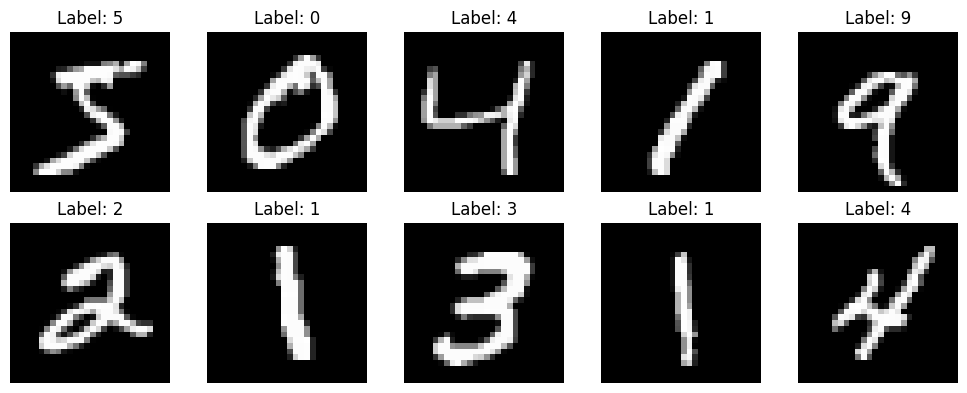

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 8. Build a small CNN

Architecture:
1. `Conv2D(25, 3)` learns 25 local feature detectors.
2. `MaxPooling2D(2)` reduces height and width.
3. A second convolution learns more complex patterns.
4. `Flatten` converts feature maps to a vector.
5. `Dense(10, softmax)` produces probabilities for the 10 digit classes.

With `padding="valid"` (the default), spatial dimensions shrink after convolution.

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(25, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(50, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 25)     │           250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 25)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 50)     │        11,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 50)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1250)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,060 (93.98 KB)

 Trainable params: 24,060 (93.98 KB)

 Non-trainable params: 0 (0.00 B)

### Predict the tensor shapes before training

Track the image dimensions through each layer. The number of channels after a convolution equals the number of filters.

In [ ]:
shape_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(25, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(50, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

for layer in shape_model.layers:
    print(f"{layer.name:20s} -> {layer.output.shape}")

conv2d_2             -> (None, 26, 26, 25)
max_pooling2d_2      -> (None, 13, 13, 25)
conv2d_3             -> (None, 11, 11, 50)
max_pooling2d_3      -> (None, 5, 5, 50)
flatten_1            -> (None, 1250)
dense_1              -> (None, 10)


## 9. Train the model

- **Loss:** sparse categorical cross-entropy is appropriate because labels are integer class IDs (0–9).
- **Optimizer:** Adam updates the model parameters using gradients.
- **Validation split:** part of the training data monitors generalization during training.
- **Epoch:** one pass through the training examples.

Results can vary slightly with runtime and random initialization.

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.9114 - loss: 0.3162 - val_accuracy: 0.9765 - val_loss: 0.0841
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - accuracy: 0.9742 - loss: 0.0862 - val_accuracy: 0.9828 - val_loss: 0.0587
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.9812 - loss: 0.0619 - val_accuracy: 0.9863 - val_loss: 0.0481
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - accuracy: 0.9842 - loss: 0.0517 - val_accuracy: 0.9865 - val_loss: 0.0469
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 47ms/step - accuracy: 0.9866 - loss: 0.0440 - val_accuracy: 0.9882 - val_loss: 0.0437


### Plot training and validation performance

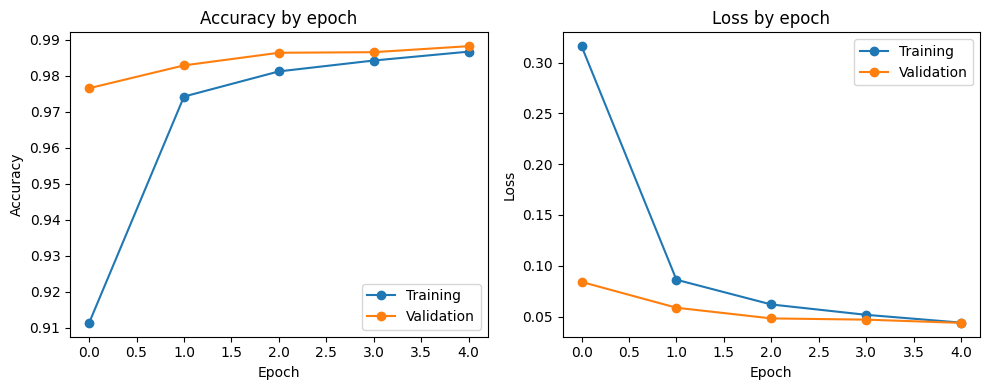

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy by epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss by epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Evaluate on unseen test images

The test set is held back during training. Its performance gives a better estimate of how the model handles images it did not train on.

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss:     0.0439
Test accuracy: 0.9856


## 11. Inspect predictions and mistakes

Accuracy summarizes performance, but looking at individual predictions helps us understand what the model gets wrong.

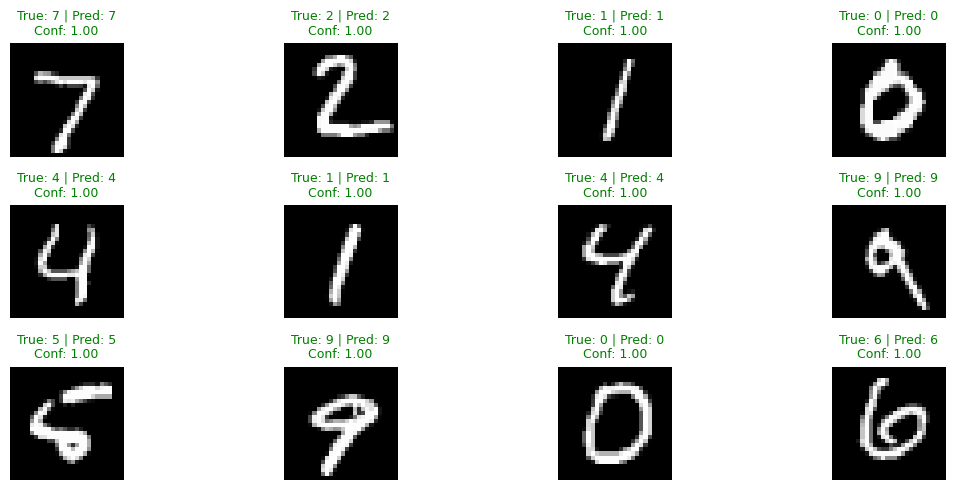

In [ ]:
probabilities = model.predict(x_test[:12], verbose=0)
predicted_labels = probabilities.argmax(axis=1)

plt.figure(figsize=(12, 5))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i, :, :, 0], cmap="gray")
    confidence = probabilities[i, predicted_labels[i]]
    color = "green" if predicted_labels[i] == y_test[i] else "red"
    plt.title(
        f"True: {y_test[i]} | Pred: {predicted_labels[i]}\nConf: {confidence:.2f}",
        color=color, fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

### Find examples the model classified incorrectly

Number of misclassified test images: 144


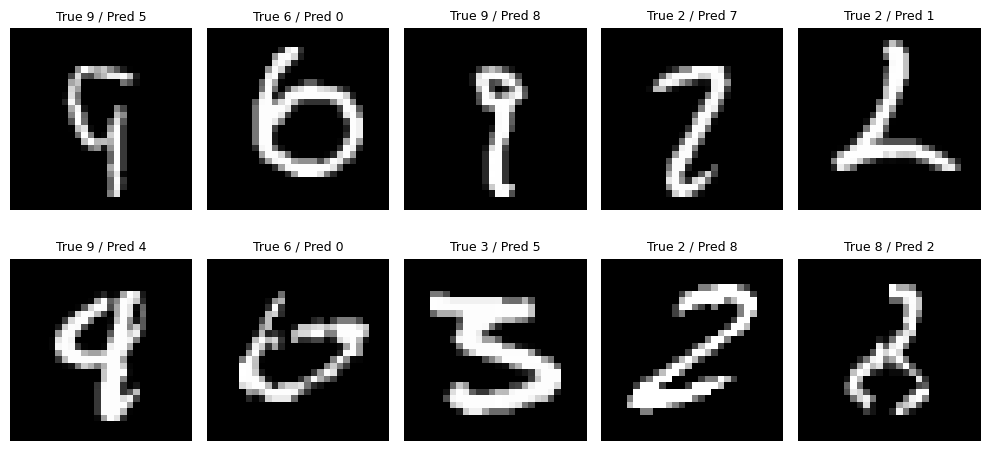

In [ ]:
all_probabilities = model.predict(x_test, batch_size=256, verbose=0)
all_predictions = all_probabilities.argmax(axis=1)
wrong_indices = np.where(all_predictions != y_test)[0]

print("Number of misclassified test images:", len(wrong_indices))

if len(wrong_indices) > 0:
    plt.figure(figsize=(10, 5))
    for plot_i, data_i in enumerate(wrong_indices[:10]):
        plt.subplot(2, 5, plot_i + 1)
        plt.imshow(x_test[data_i, :, :, 0], cmap="gray")
        plt.title(f"True {y_test[data_i]} / Pred {all_predictions[data_i]}", fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No errors found in this run.")

## 12. Review questions

Try answering these before checking your notes:

1. Why is a CNN often a better fit for images than flattening every pixel into a dense network?
2. What does a convolution filter do?


